# Assignment 3: Classification and Regression

In this assignment, I will complete two supervised learning tasks:
- Classification: I will use the Wine dataset to classify wines into three classes (Class 0, Class 1, Class 2) based on their chemical properties, using a K-Nearest Neighbors (KNN) classifier.
- Regression: I will use the Car Prices dataset to predict the price of a car based on its features, using Linear Regression.

For each task, I will load and inspect the data, split it into training and test sets, train a model, make predictions, and evaluate the model's performance.

# Part 1: Classification with the Wine Dataset

## Step 1: Import Libraries and Load the Dataset

In [13]:
# Import libraries
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

In [2]:
# Load the Wine dataset as a DataFrame
wine = load_wine(as_frame=True)
wine_df = wine.frame

In [3]:
# Basic info
print("Shape:", wine_df.shape)
print("\nFeatures:", wine.feature_names)
print("\nTarget classes:", wine.target_names)

Shape: (178, 14)

Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Target classes: ['class_0' 'class_1' 'class_2']


### Interpretation

I imported pandas and the scikit-learn tools I need for this part: load_wine to load the data, train_test_split to split it, StandardScaler for feature scaling, KNeighborsClassifier for the model, and accuracy_score and classification_report to evaluate it.

I loaded the Wine dataset as a DataFrame. It has 178 rows and 14 columns. Each row is one wine sample.

- There are 13 features, which are chemical measurements of each wine: alcohol, malic_acid, ash, alcalinity_of_ash, magnesium, total_phenols, flavanoids, nonflavanoid_phenols, proanthocyanins, color_intensity, hue, od280/od315_of_diluted_wines, and proline.
- The 14th column is the target, which shows the wine class: class_0, class_1, or class_2. These are three different cultivars (grape varieties) grown in the same region of Italy.

Since the target is a category, this is a classification problem.

## Step 2: Display the Dataset

In [5]:
# Show all columns when printing
pd.set_option("display.max_columns", None)

# Print the entire DataFrame
print(wine_df)



     alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0      14.23        1.71  2.43               15.6      127.0           2.80   
1      13.20        1.78  2.14               11.2      100.0           2.65   
2      13.16        2.36  2.67               18.6      101.0           2.80   
3      14.37        1.95  2.50               16.8      113.0           3.85   
4      13.24        2.59  2.87               21.0      118.0           2.80   
..       ...         ...   ...                ...        ...            ...   
173    13.71        5.65  2.45               20.5       95.0           1.68   
174    13.40        3.91  2.48               23.0      102.0           1.80   
175    13.27        4.28  2.26               20.0      120.0           1.59   
176    13.17        2.59  2.37               20.0      120.0           1.65   
177    14.13        4.10  2.74               24.5       96.0           2.05   

     flavanoids  nonflavanoid_phenols  proanthocyan

In [7]:
# Show the first 5 rows
print("\nFirst 5 rows:")
display(wine_df.head())




First 5 rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [8]:
# How many wines are in each class?
print("\nNumber of wines in each class:")
print(wine_df["target"].value_counts().sort_index())


Number of wines in each class:
target
0    59
1    71
2    48
Name: count, dtype: int64


### Interpretation

I printed the full DataFrame and the first 5 rows to see the structure of the data. Pandas shortens the full printout by showing only the first and last few rows, but the bottom line confirms the dataset has 178 rows and 14 columns.

From the first rows, I can see that all 13 features are numbers, but they are on very different scales. For example, proline has values in the hundreds or over 1,000, while hue and nonflavanoid_phenols are below 1. This matters for KNN, because it measures distance between data points, and large-valued features like proline would dominate the distance. This is why feature scaling is needed in Step 4.

The number of wines in each class is:
- Class 0: 59 wines
- Class 1: 71 wines
- Class 2: 48 wines

The classes are slightly uneven but fairly balanced, so I do not need special techniques like SMOTE. However, I will keep the same class proportions in my training and test sets when splitting the data.

## Step 3: Split the Data into Training and Test Sets

In [9]:
# Separate features (X) and target (y)
X_wine = wine_df.drop("target", axis=1)
y_wine = wine_df["target"]

In [10]:
# Split into 80% training and 20% testing
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=42, stratify=y_wine
)


In [11]:
print("Training set:", X_train_w.shape)
print("Test set:", X_test_w.shape)

print("\nClass counts in training set:")
print(y_train_w.value_counts().sort_index())
print("\nClass counts in test set:")
print(y_test_w.value_counts().sort_index())

Training set: (142, 13)
Test set: (36, 13)

Class counts in training set:
target
0    47
1    57
2    38
Name: count, dtype: int64

Class counts in test set:
target
0    12
1    14
2    10
Name: count, dtype: int64


### Interpretation

I separated the 13 features (X) from the target (y), then split the data into 80% training and 20% testing using train_test_split with random_state=42.

- The training set has 142 wines and the test set has 36 wines, each with 13 features. 142 + 36 = 178, so no data was lost.
- I used stratify=y_wine to keep the same class proportions in both sets. This is important because the dataset is small, and a random split could put too few wines from one class into the test set.

The class counts show that stratify worked:
- Class 0: 47 in training (33.1%) and 12 in testing (33.3%)
- Class 1: 57 in training (40.1%) and 14 in testing (38.9%)
- Class 2: 38 in training (26.8%) and 10 in testing (27.8%)

These proportions are almost the same as in the full dataset (33.1%, 39.9%, and 27.0%), so both sets represent all three wine classes fairly.

## Step 4: Feature Scaling

In [12]:
# Create the scaler
scaler = StandardScaler()

# Learn mean and std from training data, then scale it
X_train_w_scaled = scaler.fit_transform(X_train_w)

# Scale test data using the SAME mean and std from training
X_test_w_scaled = scaler.transform(X_test_w)

# Check: before vs after scaling
print("Before scaling (first 3 features, training set):")
print(X_train_w.iloc[:, :3].describe().loc[["mean", "std"]].round(2))

print("\nAfter scaling (first 3 features, training set):")
print(pd.DataFrame(X_train_w_scaled[:, :3], columns=X_wine.columns[:3])
      .describe().loc[["mean", "std"]].round(2))

Before scaling (first 3 features, training set):
      alcohol  malic_acid   ash
mean    12.97        2.34  2.36
std      0.80        1.10  0.27

After scaling (first 3 features, training set):
      alcohol  malic_acid  ash
mean      0.0        -0.0  0.0
std       1.0         1.0  1.0


### Interpretation

I used StandardScaler to standardize the features so each one has a mean of 0 and a standard deviation of 1. It uses the formula z = (x - mean) / standard deviation.

I used fit_transform on the training set, which calculates the mean and standard deviation from the training data and then scales it. For the test set, I only used transform, so it is scaled using the training set's mean and standard deviation. This prevents data leakage, because the model should not learn anything from the test data.

Before scaling, the features were on different scales. For example, alcohol had a mean of 12.97, while ash had a mean of 2.36. After scaling, all three features have a mean of 0 and a standard deviation of 1. (The -0.0 is just a very small number that rounds to zero.)

A mean of 0 does not mean every wine now has the same value. It means the average across all wines is 0. Each wine now shows how far it is above or below the average. For example, a wine with 14.0% alcohol becomes about +1.29, which means it is 1.29 standard deviations above average. The differences between wines are kept, only the unit changes.

This step is important for KNN, because KNN measures the distance between wines. Without scaling, features with large values like proline (which goes above 1,000) would control the distance, and small-valued features would be ignored.

## Step 5: Train a K-Nearest Neighbors (KNN) Classifier

### 5A: Choosing the Best Value of k with Cross-Validation

In [14]:
k_values = range(1, 22, 2)   # 1, 3, 5, ... 21
cv_scores = []

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(model, X_train_w, y_train_w, cv=5, scoring="accuracy")
    cv_scores.append(scores.mean())
    print(f"k = {k:2d}  ->  CV accuracy = {scores.mean():.4f}")

k =  1  ->  CV accuracy = 0.9367
k =  3  ->  CV accuracy = 0.9512
k =  5  ->  CV accuracy = 0.9650
k =  7  ->  CV accuracy = 0.9510
k =  9  ->  CV accuracy = 0.9650
k = 11  ->  CV accuracy = 0.9722
k = 13  ->  CV accuracy = 0.9650
k = 15  ->  CV accuracy = 0.9722
k = 17  ->  CV accuracy = 0.9791
k = 19  ->  CV accuracy = 0.9719
k = 21  ->  CV accuracy = 0.9719


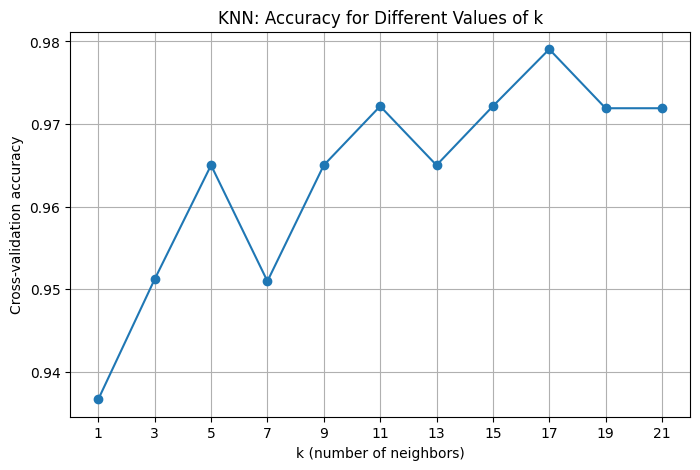


Best k: 17


In [15]:
# Plot accuracy for each k
plt.figure(figsize=(8, 5))
plt.plot(k_values, cv_scores, marker="o")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Cross-validation accuracy")
plt.title("KNN: Accuracy for Different Values of k")
plt.xticks(k_values)
plt.grid(True)
plt.show()

best_k = k_values[cv_scores.index(max(cv_scores))]
print("\nBest k:", best_k)

### Interpretation

Instead of only using k = 5, I tested different values of k (1, 3, 5, up to 21) to find the best one. I only used odd numbers to avoid ties when the neighbours vote.

To choose k fairly, I used 5-fold cross-validation on the training set only. The training data is split into 5 parts, the model trains on 4 parts and is checked on the remaining part, and this repeats 5 times. I did not use the test set here, because choosing k based on test results would make the final test score unreliable.

I also used a Pipeline that combines StandardScaler and KNN. This makes sure the scaler only learns from the training folds in each round of cross-validation, so no information leaks from the validation fold.

Results:
- k = 1 had the lowest accuracy (about 93.7%). With only one neighbour, the prediction depends on a single wine, so one unusual wine can cause a wrong prediction. This is a sign of overfitting.
- Accuracy generally increased as k got larger, and from k = 9 onwards it stayed between about 96.5% and 97.9%.
- k = 17 gave the highest cross-validation accuracy, at about 97.9%, so I chose k = 17 for my final model.
- The ups and downs in the chart (for example, k = 7 being lower than k = 5) are small. Each fold only has about 28 wines, so one wine being classified correctly or incorrectly changes the score noticeably.

### 5B: Train the Final KNN Model with the Best k

In [16]:
# Train the final KNN model with the best k
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_w_scaled, y_train_w)

print("Final KNN model trained with k =", knn.n_neighbors)
print("Number of training samples stored:", knn.n_samples_fit_)

Final KNN model trained with k = 17
Number of training samples stored: 142


### Interpretation

I trained the final KNN model using k = 17, the best value found with cross-validation. I trained it on the full scaled training set, which has 142 wines.

KNN is called a "lazy learner" because it does not learn formulas or coefficients during training. Instead, it stores all 142 training wines. When it needs to classify a new wine, it finds the 17 closest training wines and predicts the class that most of them belong to.

## Step 6: Make Predictions on the Test Set

In [17]:
# Predict the class for each wine in the test set
y_pred_w = knn.predict(X_test_w_scaled)

# Compare actual vs predicted for the first 10 test wines
comparison = pd.DataFrame({
    "Actual": y_test_w.values,
    "Predicted": y_pred_w
})
comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]

print(comparison.head(10))
print("\nCorrect predictions:", comparison["Correct"].sum(), "out of", len(comparison))

   Actual  Predicted  Correct
0       0          0     True
1       2          2     True
2       0          0     True
3       1          1     True
4       1          1     True
5       0          0     True
6       0          0     True
7       1          1     True
8       1          1     True
9       2          2     True

Correct predictions: 36 out of 36


### Interpretation

I used the trained KNN model to predict the class of each wine in the test set. I used the scaled test data, because the model was trained on scaled values.

I created a comparison table showing the actual class, the predicted class, and whether the prediction was correct. All of the first 10 predictions are correct.

Overall, the model predicted 36 out of 36 test wines correctly. This is a very strong result, but I need to keep in mind that the test set is small. With only 36 wines, a single mistake would lower accuracy to about 97.2%. The cross-validation accuracy of about 97.9% from Step 5 is probably a more realistic estimate of how well the model would perform on new wines.

## Step 7: Evaluate the Model's Performance

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



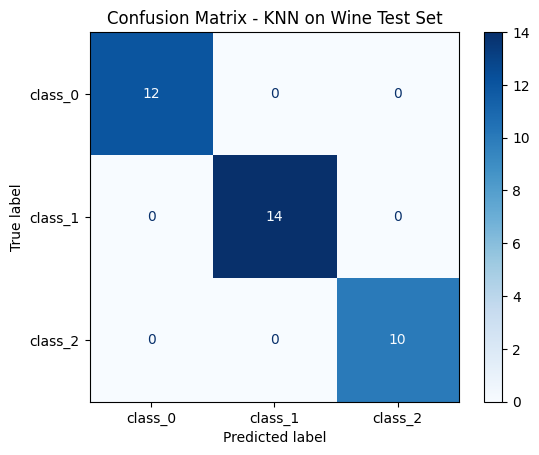

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Accuracy
accuracy = accuracy_score(y_test_w, y_pred_w)
print("Accuracy:", round(accuracy, 4))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test_w, y_pred_w, target_names=wine.target_names))

# Confusion matrix
cm = confusion_matrix(y_test_w, y_pred_w)
ConfusionMatrixDisplay(cm, display_labels=wine.target_names).plot(cmap="Blues")
plt.title("Confusion Matrix - KNN on Wine Test Set")
plt.show()

### Interpretation

Accuracy: The model reached an accuracy of 1.0 (100%), meaning all 36 test wines were classified correctly.

Classification report:
- Precision is 1.00 for all three classes. This means every time the model predicted a class, it was correct. There were no false positives.
- Recall is 1.00 for all three classes. This means the model found every wine of each class. There were no false negatives.
- F1-score is 1.00 for all classes, since both precision and recall are perfect.
- Support shows the number of test wines in each class: 12 in class_0, 14 in class_1, and 10 in class_2.
- The macro average (simple average across classes) and weighted average (average based on the number of wines in each class) are both 1.00.

Confusion matrix:
- The rows show the actual class and the columns show the predicted class.
- All the numbers are on the diagonal (12, 14, and 10), and every other cell is 0. This means no wine was confused with another class.

Although the result is perfect, the test set is small (36 wines), and the

## Part 1 Summary

- I used the Wine dataset (178 wines, 13 chemical features, 3 classes) to build a KNN classifier.
- I split the data 80/20 with stratify to keep the class proportions the same in the training and test sets.
- I standardized the features with StandardScaler because KNN uses distances, and the features were on very different scales.
- I used 5-fold cross-validation on the training set to test k values from 1 to 21. k = 17 gave the best accuracy (about 97.9%).
- The final model correctly classified all 36 test wines, with an accuracy, precision, recall, and F1-score of 1.00.

# Part 2: Regression with the Car Prices Dataset

Since no car prices dataset was provided, I used the Car Price Prediction dataset from Kaggle (CarPrice_Assignment.csv).

## Step 1: Import Libraries and Load the Dataset

In [36]:
# Import libraries for regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

In [21]:
# Load the Car Prices dataset
car_df = pd.read_csv("CarPrice_Assignment.csv")

# Basic info
print("Shape:", car_df.shape)
print("\nColumn data types:")
car_df.info()

Shape: (205, 26)

Column data types:
<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    str    
 3   fueltype          205 non-null    str    
 4   aspiration        205 non-null    str    
 5   doornumber        205 non-null    str    
 6   carbody           205 non-null    str    
 7   drivewheel        205 non-null    str    
 8   enginelocation    205 non-null    str    
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    str    
 15  cylindernumber    205 non-null    str    
 16  enginesize        

### Interpretation

I imported LinearRegression for the model, and mean_squared_error and r2_score to evaluate it. Pandas was already imported in Part 1.

I loaded the Car Prices dataset from the CSV file. It has 205 rows and 26 columns, and each row is one car.

From car_df.info():
- All 26 columns have 205 non-null values, so there are no missing values.
- 16 columns are numeric (int64 and float64). These include car measurements like wheelbase, carlength, carwidth, and curbweight, engine details like enginesize, horsepower, and peakrpm, and fuel efficiency (citympg and highwaympg).
- 10 columns are text (str), such as fueltype, carbody, drivewheel, and CarName. Linear Regression can only work with numbers, so I will need to convert these text columns into numbers before training the model.
- car_ID is just a row number, so it does not help predict price.
- The target variable is price, which is a continuous number, so this is a regression problem.

## Step 2: Display the Dataset

In [23]:
# Print the entire DataFrame
print(car_df)

     car_ID  symboling                   CarName fueltype aspiration  \
0         1          3        alfa-romero giulia      gas        std   
1         2          3       alfa-romero stelvio      gas        std   
2         3          1  alfa-romero Quadrifoglio      gas        std   
3         4          2               audi 100 ls      gas        std   
4         5          2                audi 100ls      gas        std   
..      ...        ...                       ...      ...        ...   
200     201         -1           volvo 145e (sw)      gas        std   
201     202         -1               volvo 144ea      gas      turbo   
202     203         -1               volvo 244dl      gas        std   
203     204         -1                 volvo 246   diesel      turbo   
204     205         -1               volvo 264gl      gas      turbo   

    doornumber      carbody drivewheel enginelocation  wheelbase  carlength  \
0          two  convertible        rwd          front   

In [24]:
# Show the first 5 rows
print("\nFirst 5 rows:")
display(car_df.head())


First 5 rows:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [25]:
# Summary statistics for the target
print("\nPrice statistics:")
print(car_df["price"].describe().round(2))


Price statistics:
count      205.00
mean     13276.71
std       7988.85
min       5118.00
25%       7788.00
50%      10295.00
75%      16503.00
max      45400.00
Name: price, dtype: float64


In [26]:
# How many unique values in each text column?
print("\nUnique values in text columns:")
print(car_df.select_dtypes(include="str").nunique())


Unique values in text columns:
CarName           147
fueltype            2
aspiration          2
doornumber          2
carbody             5
drivewheel          3
enginelocation      2
enginetype          7
cylindernumber      7
fuelsystem          8
dtype: int64


### Interpretation

I printed the full DataFrame and the first 5 rows to see the structure of the data. Pandas shows only the first and last rows, but confirms there are 205 rows and 26 columns.

Price statistics:
- Car prices range from $5,118 to $45,400.
- The median price is $10,295, while the mean is $13,276.71. The mean is higher than the median, which means the prices are right-skewed. Most cars are in the lower price range, and a few expensive cars pull the average up.
- The middle 50% of cars cost between $7,788 and $16,503.
- The standard deviation is about $7,989, which shows prices vary a lot.

Unique values in the text columns:
- CarName has 147 unique values out of 205 cars, so almost every car has a different name. This column cannot help the model find patterns, so I will remove it.
- The other text columns have only 2 to 8 unique values each. For example, fueltype has 2 (gas and diesel) and carbody has 5. These are categories that can be converted into numbers using one-hot encoding.

## Step 3: Split the Data into Training and Test Sets

### 3A: Prepare the Features

In [27]:
# Drop columns that don't help predict price
car_clean = car_df.drop(["car_ID", "CarName"], axis=1)

In [28]:
# One-hot encode the text columns
car_encoded = pd.get_dummies(car_clean, drop_first=True, dtype=int)

In [29]:
print("Shape before encoding:", car_clean.shape)
print("Shape after encoding:", car_encoded.shape)

Shape before encoding: (205, 24)
Shape after encoding: (205, 44)


In [30]:
# Look at a few of the new columns
print("\nExample of new columns:")
print([col for col in car_encoded.columns if col.startswith("carbody")])


Example of new columns:
['carbody_hardtop', 'carbody_hatchback', 'carbody_sedan', 'carbody_wagon']


### Interpretation

I removed two columns that do not help predict price: car_ID, which is just a row number, and CarName, which has 147 unique values out of 205 cars.

I then used pd.get_dummies to one-hot encode the text columns. This only converts the text columns into numbers. The numeric columns, like horsepower, enginesize, and price, stay the same.

Each text column was turned into several 0/1 columns, one for each category. I used drop_first=True to remove one category from each column, because it is not needed. For example, carbody had 5 types, and it became 4 columns: carbody_hardtop, carbody_hatchback, carbody_sedan, and carbody_wagon. The first type, convertible, was dropped. If a car has 0 in all four columns, it means it is a convertible. Dropping one category avoids repeating the same information, which can cause problems for Linear Regression (this is called the dummy variable trap).

The data went from 24 columns to 44 columns:
- 15 numeric columns stayed the same (14 features plus price).
- The 9 text columns had 38 categories in total. After dropping one category per column, they became 29 new 0/1 columns.
- 15 + 29 = 44 columns.

Now all columns are numeric, so the data is ready for Linear Regression.

### 3B: Split into Training and Test Sets

In [31]:
# Separate features (X) and target (y)
X_car = car_encoded.drop("price", axis=1)
y_car = car_encoded["price"]

# Split into 80% training and 20% testing
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_car, y_car, test_size=0.2, random_state=42
)

print("Training set:", X_train_c.shape)
print("Test set:", X_test_c.shape)

print("\nMean price - train:", round(y_train_c.mean(), 2))
print("Mean price - test:", round(y_test_c.mean(), 2))

Training set: (164, 43)
Test set: (41, 43)

Mean price - train: 13223.41
Mean price - test: 13489.89


### Interpretation

I separated the data into features (X) and the target (y). X has 43 columns (all features after encoding), and y is the price.

I split the data into 80% training and 20% testing with random_state=42:
- The training set has 164 cars and the test set has 41 cars, each with 43 features. 164 + 41 = 205, so no data was lost.
- I did not use stratify, because price is a continuous number, not a class.
- I did not scale the features, because Linear Regression does not use distances like KNN does. Scaling would change the size of the coefficients, but not the predictions.

The mean price is $13,223.41 in the training set and $13,489.89 in the test set. The difference is about $266, which is only about 2%. This means both sets have a similar range of car prices, so the split is fair.

## Step 4: Train a Linear Regression Model

In [32]:
# Create and train the Linear Regression model
lin_reg = LinearRegression()
lin_reg.fit(X_train_c, y_train_c)

print("Intercept:", round(lin_reg.intercept_, 2))
print("Number of coefficients:", len(lin_reg.coef_))



Intercept: -29773.17
Number of coefficients: 43


In [33]:
# Show the coefficients for some key numeric features
coef_df = pd.DataFrame({
    "Feature": X_car.columns,
    "Coefficient": lin_reg.coef_
})
key_features = ["enginesize", "horsepower", "curbweight", "carwidth", "citympg", "highwaympg"]
print("\nCoefficients for key numeric features:")
print(coef_df[coef_df["Feature"].isin(key_features)].round(2))


Coefficients for key numeric features:
       Feature  Coefficient
3     carwidth       571.52
5   curbweight         3.77
6   enginesize       123.90
10  horsepower         1.76
12     citympg      -236.15
13  highwaympg       194.13


### Interpretation

I trained a Linear Regression model on the training data. The model learned an equation in this form:

price = intercept + (coefficient 1 x feature 1) + (coefficient 2 x feature 2) + ... for all 43 features

- The intercept is the starting value of the equation. It is -29,773.17. This is the predicted price if every feature was 0 (zero width, zero weight, zero engine size). Since that kind of car cannot exist, the intercept has no real meaning by itself. It just helps the equation fit the real cars.
- A coefficient shows how much the predicted price changes when that feature increases by 1, while all other features stay the same. The model learned 43 coefficients, one for each feature.

Coefficients for some key features:
- carwidth (571.52): each extra inch of car width adds about $572 to the predicted price.
- enginesize (123.90): each extra unit of engine size adds about $124.
- curbweight (3.77): each extra pound adds about $3.77, so a car that is 500 pounds heavier would be predicted about $1,885 more expensive.
- horsepower (1.76): each extra horsepower adds only about $1.76.
- citympg (-236.15): each extra mile per gallon in the city lowers the predicted price by about $236.
- highwaympg (194.13): each extra mile per gallon on the highway raises the predicted price by about $194.

Some of these results look strange. Horsepower has a very small effect, even though more powerful cars usually cost more. Also, citympg and highwaympg have opposite signs, even though they both measure fuel efficiency. This happens because of multicollinearity: some features carry almost the same information (for example, enginesize and horsepower, or citympg and highwaympg). When this happens, the model splits the effect between them in a way that makes individual coefficients hard to trust, even if the overall predictions can still be good.

I also cannot compare coefficients directly to decide which feature is most important, because the features are on different scales. For example, curbweight is in the thousands, while carwidth is around 65.

## Step 5: Make Predictions on the Test Set

In [34]:
# Predict prices for the test set
y_pred_c = lin_reg.predict(X_test_c)

# Compare actual vs predicted prices
price_comparison = pd.DataFrame({
    "Actual Price": y_test_c.values,
    "Predicted Price": y_pred_c.round(2)
})
price_comparison["Difference"] = (price_comparison["Actual Price"] - price_comparison["Predicted Price"]).round(2)

print(price_comparison.head(10))

   Actual Price  Predicted Price  Difference
0     30760.000         28611.52     2148.48
1     17859.167         19979.31    -2120.14
2      9549.000         10737.02    -1188.02
3     11850.000         12610.95     -760.95
4     28248.000         27503.96      744.04
5      7799.000          5517.13     2281.87
6      7788.000          8391.02     -603.02
7      9258.000          7942.47     1315.53
8     10198.000          8953.44     1244.56
9      7775.000          9076.48    -1301.48


### Interpretation

I used the trained Linear Regression model to predict prices for the 41 cars in the test set. I created a table comparing the actual price, the predicted price, and the difference (actual minus predicted). This difference is called the residual.

- A positive difference means the model predicted too low.
- A negative difference means the model predicted too high.

For the first 10 test cars, the predictions are fairly close to the actual prices. Most differences are between about $600 and $2,300. The errors go in both directions, with some predictions too high and some too low, which suggests the model is not consistently over- or under-predicting.

However, the same dollar error is more serious for cheaper cars. For example, the model was off by about $2,148 for a car that costs $30,760 (about 7%), but off by about $2,282 for a car that costs $7,799 (about 29%).

## Step 6: Evaluate the Model's Performance

In [37]:
# Evaluate on the test set
mse = mean_squared_error(y_test_c, y_pred_c)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_c, y_pred_c)

print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R²) Score:", round(r2, 4))

Mean Squared Error (MSE): 8482008.48
Root Mean Squared Error (RMSE): 2912.39
R-squared (R²) Score: 0.8926
